# Lost in Translation: Mandarin to Serbian that keeps who's talking

**Track:** AI + Languages · Round 1 is judged blind, so no names or school anywhere in this notebook.

**How to run it:** in Google Colab, click **Runtime → Run all**. It needs no sign-in, no keys and no uploads, and it gives the same numbers every time. A GPU (Runtime → Change runtime type → T4 GPU) makes the translating faster but isn't required.

## 0. Intro

> Our project helps **a Mandarin speaker writing to Serbian colleagues at work** by taking **a Mandarin sentence plus who is speaking, who they're talking to and how formal it is** and giving back **Serbian with the right endings, or a warning when it had to guess**.

**The problem.** In Serbian, the words change with the speaker's gender ("I checked it" is *Проверио сам* from a man, *Проверила сам* from a woman) and with politeness (*ти си* to a friend, *Ви сте* to a boss). Mandarin marks politeness (您 is the polite "you", 你 the casual one) but usually not the speaker's gender. Many translation tools go through English on the way, and English has one "you" and no gendered verbs, so both get lost and the Serbian tends to come out masculine.

**What we compare,** on the same test sentences that we wrote ourselves:
1. **Baseline:** Mandarin → English → Serbian (two Helsinki-NLP models).
2. **Direct:** Meta's NLLB model, Mandarin straight to Serbian, its top answer.
3. **Ours:** NLLB's top 32 answers, plus rules about Serbian endings that pick the one matching the speaker, listener and formality. When none matches, repair rules try to fix the endings; if that fails too, it says "had to guess".

## 1. Setup

Installs three small extras, loads the libraries, fixes the random seed and picks the fastest hardware available.

- `sentencepiece` and `sacremoses` are what the translation models use to cut text into word pieces. `sacrebleu` gives us **chrF**, the translation score in section 7. Colab already has everything else (pandas, PyTorch, transformers, matplotlib).
- A **seed** makes anything random come out the same on every run, so the judges see exactly the numbers in our write-up. Our translations don't use randomness anyway: the models use *beam search*, which always gives the same output for the same input.

In [1]:
# Install the three extras. "-q" (quiet) keeps the output short. Takes a few seconds.
%pip install -q sentencepiece sacremoses sacrebleu

Note: you may need to restart the kernel to use updated packages.


### Libraries, seed and hardware

Import the libraries, fix the seed, and pick where the models run (`DEVICE`): an NVIDIA GPU (`cuda`, what Colab gives you under Runtime → Change runtime type → T4 GPU), else the plain processor (`cpu`). We skip a Mac's own GPU (`mps`): NLLB gave broken translations on it in our test. A GPU makes translating several times faster; without one it still works, just slower. Every model and every batch of sentences is sent to `DEVICE` in section 5.

In [2]:
import os, io, gc, time, random, urllib.request   # built into Python: files, timing, downloads
import numpy as np                 # fast maths on lists of numbers
import pandas as pd                # tables (like a spreadsheet in Python)
import matplotlib.pyplot as plt    # charts
import torch                       # PyTorch: runs the neural translation models
import transformers                # Hugging Face: downloads and runs pre-trained models
import sacrebleu                   # the chrF translation score
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

# Fix the random seed so every "Run all" gives the same results.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Use an NVIDIA GPU if there is one ("cuda", e.g. Colab's T4); otherwise the CPU.
# We don't use a Mac's own GPU ("mps"): in our test, NLLB gave broken, repeating Serbian on it
# and was slower than the CPU, while the CPU gave the right answers.
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Running on:", DEVICE, "(GPU)" if DEVICE == "cuda" else "(no GPU: slower, but it works)")

# Show whole sentences in tables instead of cutting them off with "...".
pd.set_option("display.max_colwidth", None)

print("pandas", pd.__version__, "| torch", torch.__version__,
      "| transformers", transformers.__version__, "| sacrebleu", sacrebleu.__version__)

Running on: cpu (no GPU: slower, but it works)
pandas 2.3.3 | torch 2.8.0 | transformers 4.57.6 | sacrebleu 2.6.0


### Hugging Face token (optional)

We don't need a token: all three models download with no sign-in, and we don't upload anything. This cell is only here in case we ever upload results to Hugging Face. A token would live in Colab's **Secrets** panel (the key icon on the left) under the name `HF_TOKEN`, never in this notebook. Judges won't have it, so everything below works without it.

In [3]:
HF_TOKEN = None
try:
    from google.colab import userdata   # this only exists inside Colab
    HF_TOKEN = userdata.get("HF_TOKEN")
except Exception:
    pass  # not in Colab, or no secret set: that's fine, uploading is just skipped

print("Hugging Face token found." if HF_TOKEN else "No Hugging Face token. That's fine: uploading is skipped.")

No Hugging Face token. That's fine: uploading is skipped.


### How we'll score the three systems

Every system is scored the same way, on the same **test** rows, so the comparison is fair. The scoring code comes in section 7; here is what each number means:

- **chrF:** a standard translation score (from the `sacrebleu` library). It compares our Serbian to the correct Serbian our team wrote, counting matching letter sequences, from 0 (nothing alike) to 100 (identical). It's good at noticing a wrong ending, because an ending is only a letter or two.
- **Gender correct %:** of the sentences where the speaker's (or listener's) gender shows in Serbian, how many came out with the right gender ending (for example -о vs -ла).
- **Formality correct %:** how many used the right "you": formal *Ви / сте* or casual *ти / си*.
- **Right form in the 32 options %:** how often at least one of NLLB's top 32 answers had the right gender and formality. This is the best our picker could possibly do, so it shows whether a miss is the picker's fault or the model's.
- **Flag accuracy:** when our system says "had to guess", was it really unable to find the right form? And when it doesn't warn, was it right?
- **Worst misses:** 3-5 sentences where it went most wrong, shown side by side with the correct Serbian, and why we think it happened.

## 2. Data

Our test set is a small table of everyday workplace sentences that our team wrote and labelled ourselves (how we wrote them is in `data/README.md`). We load it from the repo's public web address, never from a file on someone's laptop, so it works in a fresh Colab:

`https://raw.githubusercontent.com/proelium27/veritas-ai-hackathon/main/data/test_sentences.csv`

| Column | What it holds |
|---|---|
| `id` | a unique number for the row |
| `mandarin` | the sentence in Mandarin (simplified characters) |
| `english_meaning` | what it means, in plain English (written by us, not by a model) |
| `speaker_gender` | who is talking: `man` or `woman` |
| `listener_gender` | who they're talking to: `man`, `woman` or `group` |
| `formal` | `yes` if it uses the polite 您 (to a manager), `no` for the casual 你 |
| `what_it_tests` | which Serbian ending the sentence checks: `speaker_gender`, `listener_gender`, `formality`, or `control` (none of them); several are joined with `+` |
| `correct_serbian` | the correct Serbian in Latin letters with the marks (č, ć, š, ž, đ, dž), written by our Serbian speaker without any translation tool |
| `notes` | anything worth knowing, e.g. other correct answers |
| `split` | `practice` (used to build the picker's rules) or `test` (locked until the rules are final) |

**While the repo is still private** the web address doesn't work yet, because GitHub hides private files. So the cell falls back to a local copy: `data/test_sentences.csv` in the repo, or a `test_sentences.csv` uploaded into Colab (folder icon on the left → Upload). The repo must be public before the final check, so the judges load it from the web address.

Every column is read as text (`dtype=str`), so nothing gets changed: `yes`/`no` stay words, and empty cells become empty text instead of "NaN" (pandas' word for a missing value).

In [4]:
DATA_URL = "https://raw.githubusercontent.com/proelium27/veritas-ai-hackathon/main/data/test_sentences.csv"

# Backup places to look if the web address doesn't work yet (the repo is private until we submit).
LOCAL_COPIES = [
    "data/test_sentences.csv",      # running from the repo's top folder
    "../data/test_sentences.csv",   # running from inside the notebook/ folder
    "test_sentences.csv",           # uploaded into Colab's Files panel
]

EXPECTED_COLUMNS = ["id", "mandarin", "english_meaning", "speaker_gender", "listener_gender",
                    "formal", "what_it_tests", "correct_serbian", "notes", "split"]


def read_table(source):
    """Read the CSV with every column as text, and empty cells as empty text ("")."""
    return pd.read_csv(source, dtype=str, keep_default_na=False)


def load_test_set():
    """Return (table, where it came from). Tries the web address first, then the local copies."""
    # 1) The public web address: this is what the judges will use.
    try:
        with urllib.request.urlopen(DATA_URL, timeout=30) as response:
            text = response.read().decode("utf-8")
        return read_table(io.StringIO(text)), DATA_URL
    except Exception as error:
        print(f"Couldn't download the test set from the web address ({error}).")

    # 2) A local copy, while the repo is still private.
    for path in LOCAL_COPIES:
        if os.path.exists(path):
            print(f"Using the local copy at {path} instead.")
            return read_table(path), path

    # 3) Nothing worked: say what to do in plain English, then stop.
    print("We couldn't find our test sentences. Two ways to fix it:\n"
          "  1. Make the GitHub repo public (the judges need that anyway), then run this cell again.\n"
          "  2. While developing: in Colab, click the folder icon on the left, then Upload,\n"
          "     choose test_sentences.csv from the repo's data folder, and run this cell again.")
    raise FileNotFoundError("No test set found. See the message above.")


df, DATA_SOURCE = load_test_set()

# Check the columns are the ones we expect (a spreadsheet export can rename or drop them).
missing_columns = [c for c in EXPECTED_COLUMNS if c not in df.columns]
if missing_columns:
    raise ValueError(f"The test set is missing these columns: {missing_columns}. Compare it with data/README.md.")

# Remove stray spaces around every cell (spreadsheets sometimes add them).
df = df.apply(lambda column: column.str.strip())

print(f"Loaded {len(df)} sentences from: {DATA_SOURCE}")
if DATA_SOURCE != DATA_URL:
    print("Note: that's a local copy for development. The judges load it from the web address,")
    print("so the repo must be public before the final Run all check.")
df.head()

Couldn't download the test set from the web address (HTTP Error 404: Not Found).
Using the local copy at ../data/test_sentences.csv instead.
Loaded 60 sentences from: ../data/test_sentences.csv
Note: that's a local copy for development. The judges load it from the web address,
so the repo must be public before the final Run all check.


,id,mandarin,english_meaning,speaker_gender,listener_gender,formal,what_it_tests,correct_serbian,notes,split
0,t01,我昨天加了两个小时的班。,I worked two extra hours yesterday.,woman,man,yes,speaker_gender,Juče sam radila dva sata prekovremeno.,No 'you' in sentence; listener and formality are just the scene.,practice
1,t02,我把报告写完了。,I finished writing the report.,man,woman,yes,speaker_gender,Završio sam pisanje izveštaja.,No 'you' in sentence; listener and formality are just the scene.,practice
2,t03,我已经到车间了。,I arrived to the workshop.,woman,woman,no,speaker_gender,Stigla sam u radionicu,"No 'you' in sentence; listener and formality are just the scene. Keep 'arrived' in the past tense in Serbian (not 'I am already at...'), so the ending shows.",practice
3,t04,我今天太累了。,I am too tired today.,man,man,no,speaker_gender,Danas sam previše umoran,No 'you' in sentence; listener and formality are just the scene. Speaker gender shows in the adjective 'tired'.,test
4,t05,我忘了带安全帽。,I forgot to wear my safety helmet.,woman,group,no,speaker_gender,Zaboravila sam da stavim zaštitnu kacigu.,No 'you' in sentence; listener and formality are just the scene.,test


## 3. Explore

Before translating anything, we count the sentences by each label. This checks the set isn't lopsided: if almost every speaker were a man, a system that always writes the masculine ending would look good without being good. A blank `split` means the row is one of the example rows.

In [5]:
def tests_property(what_it_tests, prop):
    """True if a row's what_it_tests (e.g. "speaker_gender+formality") includes prop."""
    return prop in what_it_tests.split("+")

# One small table per label: how many rows have each value.
for column in ["what_it_tests", "speaker_gender", "listener_gender", "formal", "split"]:
    counts = df[column].replace("", "(blank)").value_counts().rename("rows").to_frame()
    display(counts)

# A row can test more than one thing, so also count rows per property.
print("Rows that test each property (a row can test more than one):")
for prop in ["speaker_gender", "listener_gender", "formality", "control"]:
    n = df["what_it_tests"].apply(tests_property, prop=prop).sum()
    print(f"  {prop:16s} {n}")

# Rows without the correct Serbian can be translated, but not scored.
no_serbian = (df["correct_serbian"] == "").sum()
print(f"\nRows still missing correct_serbian: {no_serbian} of {len(df)}")

,rows
what_it_tests,
speaker_gender,18
formality,12
listener_gender+formality,12
listener_gender,6
speaker_gender+formality,6
control,6


,rows
speaker_gender,
woman,30
man,30


,rows
listener_gender,
man,27
woman,27
group,6


,rows
formal,
no,33
yes,27


,rows
split,
test,45
practice,15


Rows that test each property (a row can test more than one):
  speaker_gender   24
  listener_gender  18
  formality        30
  control          6

Rows still missing correct_serbian: 0 of 60


### The same counts as a chart

One bar chart per label, side by side, so a lopsided label stands out at a glance.

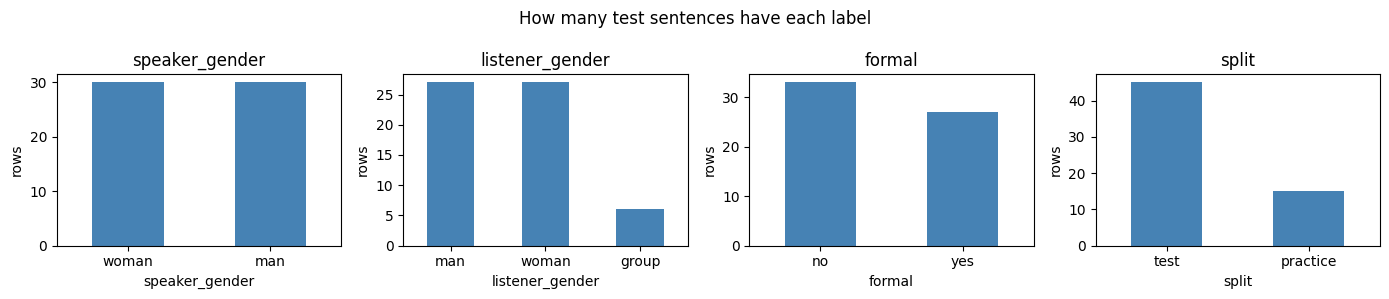

In [6]:
chart_columns = ["speaker_gender", "listener_gender", "formal", "split"]
fig, axes = plt.subplots(1, len(chart_columns), figsize=(14, 3))
for ax, column in zip(axes, chart_columns):
    df[column].replace("", "(blank)").value_counts().plot.bar(ax=ax, color="steelblue")
    ax.set_title(column)
    ax.set_ylabel("rows")
    ax.tick_params(axis="x", rotation=0)
fig.suptitle("How many test sentences have each label")
plt.tight_layout()
plt.show()

## 4. Split: practice rows and test rows

We use the `split` column exactly as our team set it when writing the sentences; we never reshuffle it or move a row after seeing results.

- **practice** (15 rows): we look at these freely and use them to write and check the picker's rules about Serbian endings.
- **test** (the rest): locked. **Nobody looks at results on the test rows until the picker's rules are final.** Otherwise we could tweak the rules until they fit the test sentences, and the score would look better than the system really is. So the tables in sections 5-7 hide test rows, and section 7 only scores them when we deliberately switch `SHOW_TEST_RESULTS` on, once.
- **example** (blank `split`): the 4 example rows from `data/README.md`. They are in neither group.

**`USE_EXAMPLES` switch:** while we were building, `USE_EXAMPLES = True` ran the whole pipeline on 4 example rows, just to show it worked. Our real 60 sentences are in the CSV now (and the example rows are gone), so it is `False`.

In [7]:
USE_EXAMPLES = False  # True: demo on the 4 example rows (only while building). Our real sentences are in now.

# Rows with an empty split are the example rows.
df["split"] = df["split"].replace("", "example")

practice = df[df.split == "practice"]
test     = df[df.split == "test"]
examples = df[df.split == "example"]
print(f"practice rows: {len(practice)} | test rows: {len(test)} | example rows: {len(examples)}")

# Anything else in the split column is probably a typo: show it so someone fixes the CSV.
odd = df[~df.split.isin(["practice", "test", "example"])]
if len(odd):
    print("These rows have an unexpected split value and are left out:")
    display(odd[["id", "split"]])

# "work" is the set of rows we translate in sections 5 and 6.
if USE_EXAMPLES:
    work = examples.copy()
    print("USE_EXAMPLES is on: translating only the example rows, as a demo.")
else:
    work = pd.concat([practice, test]).copy()
    print("Translating all practice and test rows. Test results stay hidden until the rules are final.")

if len(work) == 0:
    raise ValueError("No rows to translate. If the example rows were deleted, set USE_EXAMPLES = False.")
work = work.reset_index(drop=True)

# Tables below only show rows that are not locked test rows.
def visible(table):
    return table[table.split != "test"]

practice rows: 15 | test rows: 45 | example rows: 0
Translating all practice and test rows. Test results stay hidden until the rules are final.


## 5. Baseline: through English

Many translation apps go through English. We copy that with two pre-trained models:

1. `Helsinki-NLP/opus-mt-zh-en` translates Mandarin → English.
2. `Helsinki-NLP/opus-mt-tc-base-en-sh` translates English → Serbian. This one model covers Serbian, Croatian and Bosnian, so each input starts with `>>srp_Cyrl<<` to ask for Serbian in Cyrillic letters.

We expect this route to lose the speaker's gender and the formal/casual "you", because English doesn't have them. We keep the English in the middle (`english_model`) so you can see where the information disappears.

First, the helpers we use for every model. `load()` downloads a model and its **tokenizer** (the part that cuts text into the word pieces the model reads). `translate()` runs a model on a list of sentences, a few at a time (a small *batch*, so a laptop doesn't run out of memory), using **beam search**: the model keeps its best few guesses at each step and returns the best ones, most likely first. It prints a progress line after each batch. `free_memory()` hands memory back after each step.

In [8]:
def load(name, **tokenizer_options):
    """Download a translation model and its tokenizer (only the first time), and put it on DEVICE."""
    start = time.time()
    tokenizer = AutoTokenizer.from_pretrained(name, **tokenizer_options)
    model = AutoModelForSeq2SeqLM.from_pretrained(name).to(DEVICE).eval()   # eval() = use it, not train it
    print(f"Loaded {name} in {time.time() - start:.0f} s")
    return tokenizer, model


def free_memory():
    """Give memory back after a step: Python's leftovers first, then the GPU's cache."""
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    elif DEVICE == "mps":
        torch.mps.empty_cache()


def translate(tokenizer, model, texts, n_options=1, batch_size=4, **generate_options):
    """Translate a list of sentences, a few at a time (batch_size), printing progress.
    Returns one list per sentence holding its n_options best translations, best first.
    Small batches keep memory low: 32 options for 16 sentences at once filled a 16 GB laptop."""
    results = []
    start = time.time()
    for first in range(0, len(texts), batch_size):
        chunk = texts[first:first + batch_size]
        batch = tokenizer(chunk, return_tensors="pt", padding=True).to(DEVICE)
        with torch.inference_mode():                               # no training, so skip the extra maths
            output = model.generate(**batch,
                                    num_beams=max(4, n_options),   # how many guesses beam search keeps
                                    num_return_sequences=n_options,
                                    max_new_tokens=128,            # plenty for one short sentence
                                    **generate_options)
        decoded = tokenizer.batch_decode(output, skip_special_tokens=True)
        # The model returns one flat list; regroup it into n_options per sentence.
        for i in range(len(chunk)):
            results.append(decoded[i * n_options:(i + 1) * n_options])
        del batch, output                                          # drop the big tensors before the next batch
        free_memory()
        print(f"  {len(results)}/{len(texts)} done, {time.time() - start:.1f} s")
    return results

### Serbian in Latin letters: `to_latin()`

Serbian is written in two alphabets, Cyrillic and Latin, and our correct answers are in **Latin** (with the marks č, ć, š, ž, đ, dž). But the models can only write Serbian in **Cyrillic**: NLLB has a "Serbian, Cyrillic" setting (`srp_Cyrl`) and no "Serbian, Latin" one (its Latin options are Croatian and Bosnian, which are different languages with different words), and we ask the English → Serbian model for Cyrillic too.

That's not a problem, because the two Serbian alphabets match **letter for letter**: ш is always š, ч is always č, and three Cyrillic letters become two Latin ones (љ → lj, њ → nj, џ → dž). So converting is exact, with no guessing and nothing lost. Every model answer is converted to Latin as soon as it's produced, and the Cyrillic original is kept in an extra column ending in `_cyrillic`. The cell also tests the conversion on a few words.

In [9]:
# Serbian Cyrillic -> Latin, one letter at a time (small letters first).
CYRILLIC_TO_LATIN = {
    "а": "a", "б": "b", "в": "v", "г": "g", "д": "d", "ђ": "đ", "е": "e", "ж": "ž", "з": "z", "и": "i",
    "ј": "j", "к": "k", "л": "l", "љ": "lj", "м": "m", "н": "n", "њ": "nj", "о": "o", "п": "p", "р": "r",
    "с": "s", "т": "t", "ћ": "ć", "у": "u", "ф": "f", "х": "h", "ц": "c", "ч": "č", "џ": "dž", "ш": "š",
}
# Capital letters: Ш -> Š, and Љ -> "Lj" (not "LJ"), because a capital usually just starts a word.
CYRILLIC_TO_LATIN.update({cyr.upper(): lat.capitalize() for cyr, lat in list(CYRILLIC_TO_LATIN.items())})


def to_latin(text):
    """Write Serbian Cyrillic in Latin letters. Anything else (Latin, punctuation, spaces) stays as it is."""
    return "".join(CYRILLIC_TO_LATIN.get(letter, letter) for letter in text)


# Test it on a few words where we know the right answer.
checks = {"Проверила сам": "Proverila sam", "Љубав": "Ljubav", "Џеп": "Džep", "Ђак": "Đak",
          "Ћерка": "Ćerka", "Чаша, шешир, жут, цвет, јуче": "Čaša, šešir, žut, cvet, juče",
          "Њива": "Njiva", "Already Latin: šta": "Already Latin: šta"}
for cyrillic, expected in checks.items():
    result = to_latin(cyrillic)
    print("ok " if result == expected else "WRONG", f"{cyrillic} -> {result}")
    assert result == expected, f"to_latin({cyrillic!r}) gave {result!r}, expected {expected!r}"

ok  Проверила сам -> Proverila sam
ok  Љубав -> Ljubav
ok  Џеп -> Džep
ok  Ђак -> Đak
ok  Ћерка -> Ćerka
ok  Чаша, шешир, жут, цвет, јуче -> Čaša, šešir, žut, cvet, juče
ok  Њива -> Njiva
ok  Already Latin: šta -> Already Latin: šta


### Load the two baseline models

Each is loaded once and reused for every sentence. The first run downloads them (about 300 MB each), which takes a minute or two.

In [10]:
zh_en_tok, zh_en = load("Helsinki-NLP/opus-mt-zh-en")           # Mandarin -> English
en_sr_tok, en_sr = load("Helsinki-NLP/opus-mt-tc-base-en-sh")   # English -> Serbian/Croatian/Bosnian

Loaded Helsinki-NLP/opus-mt-zh-en in 17 s


Loaded Helsinki-NLP/opus-mt-tc-base-en-sh in 22 s


### Translate every row through English

Step 1 gives `english_model`, step 2 gives the Serbian: `baseline` in Latin letters (what we score) and `baseline_cyrillic` (what the model wrote). The table shows them next to our correct Serbian. Test rows are translated too, but hidden.

In [11]:
start = time.time()
mandarin = work["mandarin"].tolist()

# Step 1: Mandarin -> English (take the top answer for each sentence).
work["english_model"] = [options[0] for options in translate(zh_en_tok, zh_en, mandarin)]

# Step 2: English -> Serbian. ">>srp_Cyrl<<" asks for Serbian in Cyrillic.
english_inputs = [">>srp_Cyrl<< " + english for english in work["english_model"]]
work["baseline_cyrillic"] = [options[0] for options in translate(en_sr_tok, en_sr, english_inputs)]
work["baseline"] = work["baseline_cyrillic"].apply(to_latin)   # Latin, like our correct answers

print(f"Baseline: translated {len(work)} sentences in {time.time() - start:.1f} s")
visible(work)[["id", "mandarin", "english_meaning", "english_model", "baseline", "correct_serbian"]]

  4/60 done, 0.2 s
  8/60 done, 0.4 s


  12/60 done, 0.5 s
  16/60 done, 0.7 s


  20/60 done, 0.8 s
  24/60 done, 1.0 s


  28/60 done, 1.1 s
  32/60 done, 1.3 s


  36/60 done, 1.4 s
  40/60 done, 1.6 s


  44/60 done, 1.8 s
  48/60 done, 1.9 s


... (7 outputs left out)

  40/60 done, 1.8 s
  44/60 done, 2.0 s


  48/60 done, 2.2 s
  52/60 done, 2.3 s


  56/60 done, 2.5 s
  60/60 done, 2.7 s
Baseline: translated 60 sentences in 5.1 s


,id,mandarin,english_meaning,english_model,baseline,correct_serbian
0,t01,我昨天加了两个小时的班。,I worked two extra hours yesterday.,I added two hours yesterday.,Dodao sam dva sata juče.,Juče sam radila dva sata prekovremeno.
1,t02,我把报告写完了。,I finished writing the report.,I've finished my report.,Završio sam izveštaj.,Završio sam pisanje izveštaja.
2,t03,我已经到车间了。,I arrived to the workshop.,I've been to the workshop.,Bio sam u radionici.,Stigla sam u radionicu
3,t06,我刚才看见叉车撞到货架了。,I just saw a forklift hit the shelves.,I just saw the forklift hit the shelf.,Upravo sam video viljuškar udario polici.,Upravo sam video kako je viljuškar udario u police
4,t22,你看到我的手套了吗？,Did you see my gloves?,Did you see my gloves?,Jesi li video moje rukavice?,Da li si video moje rukavice?
5,t23,你昨天几点走的？,When did you leave yesterday?,What time did you leave yesterday?,Kada ste juče otišli?,Kada si juče otišla?
6,t25,您需要帮忙吗？,Do you need help?,Can I help you?,Mogu li vam pomoći?,Da li vam treba pomoć?
7,t26,你需要帮忙吗？,Do you need help?,Do you need some help?,Treba li ti pomoć?,Da li ti treba pomoć?
8,t33,您要喝杯咖啡吗？,Do you need a cup of coffee?,Would you like a cup of coffee?,Želite li šolju kafe?,Hoćete li šolju kafe?
9,t39,我刚才给您打过电话。,I just called you.,I just called you.,Upravo sam te zvao.,Upravo sam Vas zvao.


## 6. Main model: NLLB direct, then NLLB + our picker

`facebook/nllb-200-distilled-600M` (NLLB, "No Language Left Behind", by Meta) translates directly between 200 languages, so Mandarin (`zho_Hans`) goes straight to Serbian in Cyrillic (`srp_Cyrl`) with no English in the middle.

We ask NLLB for its **top 32** answers per sentence (`options`), using beam search with 32 guesses. We tested 8, 16 and 32 in `more_options.ipynb`: with 32, a version with the right ending was there for 91% of sentences, against 80% with 8, and it is still fast. Its first answer is the **direct** system. As with the baseline, every answer is converted to Latin letters with `to_latin()`; the Cyrillic originals are kept in `options_cyrillic` and `direct_cyrillic`. The 32 options are what our picker chooses from, so we also save them to a CSV file that teammates can open and reuse without running the model again.

In [12]:
# The baseline models are done: free them before loading NLLB, so a laptop doesn't run out of memory.
# (The demo in section 8 loads them again if it needs them; they are already downloaded, so that's quick.)
del zh_en, en_sr
free_memory()

# src_lang tells the tokenizer the input is Mandarin in simplified characters.
nllb_tok, nllb = load("facebook/nllb-200-distilled-600M", src_lang="zho_Hans")

# NLLB must be told the output language: we force the first word to be the "Serbian, Cyrillic" tag.
SERBIAN = nllb_tok.convert_tokens_to_ids("srp_Cyrl")

Loaded facebook/nllb-200-distilled-600M in 82 s


### Translate every row directly: top 32 options, and the top answer as "direct"

In [13]:
N_OPTIONS = 32

start = time.time()
# One sentence at a time (batch_size=1): 32 options per sentence already makes a big batch.
work["options_cyrillic"] = translate(nllb_tok, nllb, work["mandarin"].tolist(), n_options=N_OPTIONS,
                                     batch_size=1, forced_bos_token_id=SERBIAN)
# Convert every option to Latin letters (see to_latin in section 5).
work["options"] = [[to_latin(option) for option in options] for options in work["options_cyrillic"]]
work["direct_cyrillic"] = [options[0] for options in work["options_cyrillic"]]
work["direct"] = [options[0] for options in work["options"]]   # NLLB's single best answer, in Latin
print(f"NLLB: {N_OPTIONS} options for each of {len(work)} sentences in {time.time() - start:.1f} s")

visible(work)[["id", "mandarin", "direct", "correct_serbian"]]

  1/60 done, 1.8 s


  2/60 done, 2.6 s


  3/60 done, 3.3 s


  4/60 done, 4.8 s


  5/60 done, 5.6 s


  6/60 done, 6.4 s


... (51 outputs left out)

  58/60 done, 61.5 s


  59/60 done, 62.3 s


  60/60 done, 63.3 s
NLLB: 32 options for each of 60 sentences in 63.3 s


,id,mandarin,direct,correct_serbian
0,t01,我昨天加了两个小时的班。,Ja sam dodao dva sata u rad juče.,Juče sam radila dva sata prekovremeno.
1,t02,我把报告写完了。,Spisao sam izveštaj.,Završio sam pisanje izveštaja.
2,t03,我已经到车间了。,Došao sam u radionicu.,Stigla sam u radionicu
3,t06,我刚才看见叉车撞到货架了。,To što sam video je da se vinka udari u policu.,Upravo sam video kako je viljuškar udario u police
4,t22,你看到我的手套了吗？,Vidiš li moje rakavice?,Da li si video moje rukavice?
5,t23,你昨天几点走的？,Koliko si otišao juče?,Kada si juče otišla?
6,t25,您需要帮忙吗？,Da li vam je potrebna pomoć?,Da li vam treba pomoć?
7,t26,你需要帮忙吗？,Da li vam je potrebna pomoć?,Da li ti treba pomoć?
8,t33,您要喝杯咖啡吗？,Da li želite kafu?,Hoćete li šolju kafe?
9,t39,我刚才给您打过电话。,Samo sam vam se javio.,Upravo sam Vas zvao.


### Save the 32 options to CSV files

One row per sentence, with columns `option_1` to `option_32` (in Latin letters, like our correct answers). Practice and example rows go in one file, which our Serbian speaker can read while writing the picker's rules. Test rows go in a separate file marked LOCKED, which nobody opens until the rules are final. In Colab, the files appear in the `outputs` folder of the Files panel (folder icon on the left), where you can download them.

In [14]:
OUTPUT_DIR = "outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Spread the list of options into one column per option.
options_table = work[["id", "split", "mandarin", "speaker_gender", "listener_gender", "formal"]].copy()
for k in range(N_OPTIONS):
    options_table[f"option_{k + 1}"] = [options[k] for options in work["options"]]

files = {
    "nllb_options.csv": options_table[options_table.split != "test"],
    "nllb_options_TEST_LOCKED.csv": options_table[options_table.split == "test"],
}
for filename, table in files.items():
    if len(table):
        path = os.path.join(OUTPUT_DIR, filename)
        table.to_csv(path, index=False, encoding="utf-8")
        print(f"Saved {len(table)} rows to {path}")

Saved 15 rows to outputs/nllb_options.csv
Saved 45 rows to outputs/nllb_options_TEST_LOCKED.csv


### Reading the endings: `detect()`

This is the heart of our picker. `detect()` reads one Serbian sentence (in Latin letters) and says what it shows: the **speaker's gender**, the **listener's gender** and whether the "you" is **formal**. Our Serbian speaker checked and corrected every rule below, using only the practice rows, and then answered 10 follow-up questions (marked *Answer Q1* to *Q10* in the code comments).

**Speaker's gender.** Serbian marks "I did" with a little helper word, *sam* ("I am") or *nisam* ("I am not"), next to a past form. A man says *Proverio **sam***, a woman *Proverila **sam***. So we look at the word right before *sam* and up to 3 words after it:
- ends in **-la** → a woman (*proverila*, *došla*); ends in **-o** (-ao, -eo, -io, -uo) → a man (*proverio*, *došao*, *video*, *čuo*).
- describing words from a fixed list: *spreman* (man) / *spremna* (woman), *umoran* / *umorna*, and so on, plus *sama* ("alone", a woman).
- *sam* can also mean "alone" (a man). The helper *sam* never starts a sentence, so a first-word *Sam* means "alone"; and if the same part of the sentence already has *je, si, smo, ste* or *su* before it (*Ostao je sam*, "he stayed alone"), it means "alone" too.
- words that only look like a man's verb are ignored: *kao* (like), *posao* (job), *deo* (part), *ceo*, *pepeo*, *orao*, *žao*, *zao*, *sto*; and nouns that end in -la: *posla, stola, pola, škola, kola* (*Posle posla sam otišao* is a man). A sentence that shows both genders is flagged "mixed".
- we stop looking at punctuation and at *da, što, koji, koja, kad, ali*, because after those the verb can belong to someone else: in *Rekao sam da je ona došla* the speaker is a man.

**Listener's gender.** The same idea with the casual "you are": *si*, *jesi*, *nisi*. *Da li si **došla**?* is asked to a woman. Formal *Vi* always takes the plural (*Jeste li došli?*) for a man or a woman, so on formal rows the listener's gender can't show and we never check it.

**Formality.** Formal signs: *Vi, Vas, Vam, Vaš* (all its forms), *ste, jeste, niste, biste*, verbs ending in **-te** (*možete, znate*), formal commands (*Potpišite*), *nemojte*, *molim Vas*. Casual signs: *ti, tebe, tebi, tobom, tvoj* (all its forms), *si, jesi, nisi*, verbs ending in **-š** (*možeš, znaš*), casual commands (*Potpiši, Čekaj*), *nemoj*, *molim te*. A few look-alikes are ignored (*još, baš, naš, loš* end in -š; *dete, karte, minute* end in -te). Commands are only checked on the first word (or the word after *molim te / Vas*), otherwise words like *taj* or *moj* would count. A first word ending in **-ti** or **-ći** is an infinitive (*doći, reći, raditi*), not a command, so *Doći ću sutra* ("I will come tomorrow") no longer looks casual.

**The word *te*.** It means casual "you" in *Vidim te*, but also "those" or "and so". A rule would miss cases, so we marked by hand the practice rows whose *te* means "you" (`TE_MEANS_YOU`, only *t39*). On every other row *te* counts only in *molim te*.

Each answer is `"man"` / `"woman"` or `"yes"` / `"no"`, the same words as our labels. `None` means the sentence doesn't show it. `"mixed"` means it shows both (for example *ti* and *Vam* in one sentence), which is always counted as wrong.

In [15]:
import re

# ---- Word lists, all taken from our Serbian speaker's checked rules ----
# A comment like "# Answer Q4" points to our Serbian speaker's answer to our 4th follow-up question
# (listed in docs/log.md, Sat Nov 14).

# Helper words. "sam" / "nisam" = "I am" / "I am not": the word next to them shows the SPEAKER's gender.
# "si" / "jesi" / "nisi" = casual "you are": the word next to them shows the LISTENER's gender.
SPEAKER_HELPERS = {"sam", "nisam"}
LISTENER_HELPERS = {"si", "jesi", "nisi"}
# Answer Q1: "sama", "samo", "sami", "same" are never the helper, so they are not in the list above.
# Other forms of "to be" (is, you are, we are, you all are, they are). If the clause already has one,
# a "sam" in it means "alone", not "I am": "Ostao je sam" = "He stayed alone".
OTHER_BE_WORDS = {"je", "si", "smo", "ste", "su"}

# After these words the next verb can belong to someone else ("Rekao sam da je ona došla"), so we stop looking.
STOP_WORDS = {"da", "što", "koji", "koja", "kad", "ali"}
LOOK_AHEAD = 3   # how many words after the helper we look at

# Words that end like a man's past form (-ao, -eo, -io, -uo) but are not verbs.
NOT_VERBS = {"kao", "posao", "deo", "ceo", "pepeo", "orao", "žao", "zao", "sto"}
# Answer Q9: nouns that end in -la like a woman's past form ("Posle posla sam otišao" is a man).
NOT_LA_VERBS = {"posla", "stola", "pola", "škola", "kola"}

# Describing words (adjectives): the man's form and the woman's form.
ADJECTIVES = {"spreman": "spremna", "umoran": "umorna", "siguran": "sigurna", "gladan": "gladna",
              "srećan": "srećna", "zadovoljan": "zadovoljna", "bolestan": "bolesna", "svestan": "svesna",
              "radostan": "radosna", "gotov": "gotova", "povređen": "povređena", "zauzet": "zauzeta",
              "kriv": "kriva", "zaposlen": "zaposlena", "ljut": "ljuta"}
MAN_ONLY_WORDS = {"umro"}      # Answer Q3: the man's form of umrla ("died") doesn't end in -ao/-eo/-io/-uo
WOMAN_ONLY_WORDS = {"sama"}   # "Sama sam kod kuće" = a woman. (A "sam" that means "alone" is handled below.)

# Formal "you": Vi / Vas / Vam, every form of Vaš, ste / jeste / niste / biste, nemojte.
FORMAL_WORDS = {"vi", "vas", "vam", "vama", "vaš", "vaša", "vaše", "vašeg", "vašem", "vašu", "vašim",
                "vašoj", "vaših", "vašima", "ste", "jeste", "niste", "biste", "nemojte"}
# Casual "you": ti / tebe / tebi / tobom, every form of tvoj, si / jesi / nisi, nemoj.
# ("te" is left out: it also means "those" and "and so". Only "molim te" counts, plus the rows below.)
INFORMAL_WORDS = {"ti", "tebe", "tebi", "tobom", "tvoj", "tvoja", "tvoje", "tvog", "tvom", "tvoju",
                  "tvojim", "tvojoj", "tvojih", "tvome", "si", "jesi", "nisi", "nemoj"}
NOT_TE_VERBS = {"dete", "plate", "karte", "minute", "kante"}   # nouns that end in -te
NOT_Š_VERBS = {"još", "baš", "naš", "loš", "keš", "vaš"}        # words that end in -š but aren't casual verbs
NOT_COMMANDS = {"taj", "moj", "kraj", "li", "mi"}               # end in -i / -j but aren't commands

# Answer Q6: a rule for "te" would miss "Vidim te" and "Pitao sam te", so we mark by hand the rows
# whose "te" means casual "you". Built from the PRACTICE rows only: t39 ("I just called you"), where
# the casual way to say it is "Pozvao sam te". Test rows are never marked, so on them "te" counts
# only in "molim te".
TE_MEANS_YOU = {"t39"}


def split_words(sentence):
    """Cut a sentence into [gap, word, gap, word, ..., gap]. Words are at the odd positions;
    a gap is the spaces and punctuation between two words. Joining the pieces gives the sentence back."""
    return re.split(r"(\w+)", sentence)


def words_and_breaks(sentence):
    """The words in lowercase, and for each word whether punctuation comes right after it."""
    pieces = split_words(sentence)
    words = [w.lower() for w in pieces[1::2]]
    breaks = [pieces[2 * k + 2].strip() != "" for k in range(len(words))]
    return words, breaks


def clause_span(words, breaks, i):
    """Where the part of the sentence holding word i starts and ends (both positions included).
    We cut at punctuation and before a stop word."""
    start = i
    while start > 0 and not breaks[start - 1] and words[start] not in STOP_WORDS:
        start -= 1
    end = i
    while end + 1 < len(words) and not breaks[end] and words[end + 1] not in STOP_WORDS:
        end += 1
    return start, end


def clause(words, breaks, i):
    """The words in the same part of the sentence as word i."""
    start, end = clause_span(words, breaks, i)
    return words[start:end + 1]


def helper_spots(words, breaks, helpers):
    """Positions of the words that really are helpers.
    Answer Q1: the helper "sam" never starts a sentence, so a first-word "Sam" means "alone"; and if its
    clause already has je/si/smo/ste/su ("Ostao je sam"), that "sam" means "alone" too.
    We only look for je/si/... BEFORE "sam": in "Video sam kako je pao" the "je" comes later and
    belongs to the next part ("how it fell"), so that "sam" is still the helper."""
    spots = []
    for i, word in enumerate(words):
        if word not in helpers:
            continue
        start, _ = clause_span(words, breaks, i)
        if word == "sam" and (i == 0 or OTHER_BE_WORDS & set(words[start:i])):
            continue                                       # "sam" = alone, not "I am"
        spots.append(i)
    return spots


def near_helpers(words, breaks, helpers):
    """Positions of the words next to a helper word: the word right before it, and up to
    LOOK_AHEAD words after it, stopping at punctuation or a stop word."""
    positions = []
    for i in helper_spots(words, breaks, helpers):
        if i > 0 and not breaks[i - 1]:
            positions.append(i - 1)
        for j in range(i + 1, min(i + 1 + LOOK_AHEAD, len(words))):
            if breaks[j - 1] or words[j] in STOP_WORDS:
                break
            positions.append(j)
    return positions


def word_gender(word):
    """'man', 'woman' or None for one lowercase word: a past form (-o / -la) or a describing word."""
    if word in ADJECTIVES or word in MAN_ONLY_WORDS:
        return "man"
    if word in ADJECTIVES.values() or word in WOMAN_ONLY_WORDS:
        return "woman"
    if word in NOT_VERBS or word in NOT_LA_VERBS:
        return None
    if word.endswith(("ao", "eo", "io", "uo")):
        return "man"
    if word.endswith("la") and len(word) >= 4:
        return "woman"
    return None


def is_alone_sam(words, breaks, k):
    """True if word k is a "sam" that means "alone" (a man's word), not the helper (Answer Q1)."""
    return words[k] == "sam" and k not in helper_spots(words, breaks, SPEAKER_HELPERS)


def gender_near(words, breaks, helpers):
    """The gender shown by the words next to the helpers: 'man', 'woman',
    'mixed' (both show up, which is always wrong) or None (no sign).
    Answer Q9: a sentence that shows both genders is flagged as 'mixed'."""
    found = set()
    for k in near_helpers(words, breaks, helpers):
        found.add("man" if is_alone_sam(words, breaks, k) else word_gender(words[k]))
    found -= {None}
    if len(found) == 2:
        return "mixed"
    return found.pop() if found else None


def command_word(words):
    """The word that would be a command: the first word, or the word after "molim te" / "molim Vas"."""
    for i in range(len(words) - 2):
        if words[i] == "molim" and words[i + 1] in ("te", "vas"):
            return words[i + 2]
    return words[0] if words else ""


def formality(words, te_means_you=False):
    """'yes' (formal Vi), 'no' (casual ti), 'mixed' (both, always wrong) or None (no sign)."""
    formal = informal = False
    for word in words:
        if word in FORMAL_WORDS or (len(word) >= 5 and word.endswith("te") and word not in NOT_TE_VERBS):
            formal = True
        if word in INFORMAL_WORDS or (word.endswith("š") and word not in NOT_Š_VERBS):
            informal = True
    if any(a == "molim" and b == "te" for a, b in zip(words, words[1:])):
        informal = True                                   # "molim te" = casual "please"
    if te_means_you and "te" in words:
        informal = True                                   # Answer Q6: a hand-marked row, "te" = casual "you"
    command = command_word(words)
    if command in FORMAL_WORDS or command in INFORMAL_WORDS:
        pass                                              # a "you" word, already counted above
    elif command.endswith(("ite", "ajte", "jte")):
        formal = True                                     # Potpišite, Čekajte: formal command
    elif command.endswith(("ti", "ći")):
        pass                                              # Answer Q2: doći, reći, raditi are infinitives, never
                                                          # commands (risk: a missing mark, reci vs reći)
    elif command.endswith(("i", "j")) and command not in NOT_COMMANDS:
        informal = True                                   # Potpiši, Čekaj: casual command
    if formal and informal:
        return "mixed"
    return "yes" if formal else "no" if informal else None


def detect(serbian, te_means_you=False):
    """Read one Serbian sentence (Latin letters) and say what it shows.
    Returns speaker ('man'/'woman'), listener ('man'/'woman') and formal ('yes'/'no');
    None means the sentence doesn't show it, 'mixed' means it shows both (always counted wrong).
    te_means_you=True for the hand-marked rows where "te" means casual "you" (Answer Q6)."""
    words, breaks = words_and_breaks(serbian)
    return dict(speaker=gender_near(words, breaks, SPEAKER_HELPERS),
                listener=gender_near(words, breaks, LISTENER_HELPERS),
                formal=formality(words, te_means_you))


def detect_row(serbian, row):
    """detect() for one row of our table: also passes whether this row's "te" means "you"."""
    return detect(serbian, te_means_you=row.get("id") in TE_MEANS_YOU)

### Hand tests for `detect()`

Before trusting `detect()` on model output, we test it on short sentences where we know the answer, most of them taken straight from our Serbian speaker's rule sheet (including the tricky cases added during review, like *Rekao sam da je ona došla* and *Završila sam posao*). The cell stops with an error if any test fails. Newer tests use our Serbian speaker's own example words from his answers (*Ostao je sam*, *Posle posla sam otišao*, *Doći ću sutra*, *Vidim te*). It also prints the known limits: a casual command ending in -ti (*Vrati to*, "give it back") looks like an infinitive, a missing mark makes *Reci* and *Reći* look the same, and *te* on a row that isn't hand-marked doesn't count as "you".

In [16]:
# Hand tests: sentences from our Serbian speaker's rule sheet, with the answer we expect.
# Each line: sentence, then the expected (speaker, listener, formal). None = doesn't show.
DETECT_TESTS = [
    ("Proverila sam.",                       ("woman", None, None)),
    ("Nisam čula.",                          ("woman", None, None)),
    ("Proverio sam.",                        ("man", None, None)),
    ("Već sam ga isključila.",               ("woman", None, None)),
    ("Ja sam joj to rekla.",                 ("woman", None, None)),
    ("Već sam Vam to poslala.",              ("woman", None, "yes")),
    ("Juče sam se razbolela.",               ("woman", None, None)),
    ("Rekao sam da je ona došla.",           ("man", None, None)),   # došla is after "da": someone else
    ("Završila sam posao.",                  ("woman", None, None)), # posao is a noun, not a man's verb
    ("Veseo sam.",                           ("man", None, None)),
    ("Umorna sam.",                          ("woman", None, None)), # describing word before sam
    ("Danas sam umoran.",                    ("man", None, None)),
    ("Sama sam kod kuće.",                   ("woman", None, None)),
    ("Posao je gotov.",                      (None, None, None)),    # gotov describes the job, no sam
    ("Treba mi pomoć.",                      (None, None, None)),
    ("Kada si juče otišla?",                 (None, "woman", "no")),
    ("Da li si došao?",                      (None, "man", "no")),
    ("Jesi li povređena?",                   (None, "woman", "no")),
    ("Jesi li umoran?",                      (None, "man", "no")),
    ("Zar nisi došla?",                      (None, "woman", "no")),
    ("Vidiš li moje rukavice?",              (None, None, "no")),    # present tense: no gender
    ("Jeste li došli?",                      (None, None, "yes")),   # formal plural: no gender
    ("Da li Vam treba pomoć?",               (None, None, "yes")),
    ("Vaš paket je na portirnici.",          (None, None, "yes")),
    ("Možete li sutra da dođete ranije?",    (None, None, "yes")),
    ("Možeš li sutra da dođeš ranije?",      (None, None, "no")),
    ("Tvoja kartica je ovde.",               (None, None, "no")),
    ("Imam još karte.",                      (None, None, None)),    # još and karte are not "you" words
    ("Potpišite se ovde.",                   (None, None, "yes")),
    ("Potpiši se ovde.",                     (None, None, "no")),
    ("Molim Vas, sačekajte.",                (None, None, "yes")),
    ("Molim te, sačekaj.",                   (None, None, "no")),
    ("Taj čovek je ovde.",                   (None, None, None)),    # taj is not a command
    ("Nemojte to.",                          (None, None, "yes")),
    ("Nemoj to.",                            (None, None, "no")),
    ("Da li ti treba pomoć, molim Vas?",     (None, None, "mixed")), # both kinds of "you": always wrong
    # Answer Q1: "sam" can also mean "alone".
    ("Ostao je sam.",                        (None, None, None)),    # "je" is there, so sam = alone
    ("Jutros je sam došao.",                 (None, None, None)),    # he came alone: not the speaker
    ("Sam sam završio posao.",               ("man", None, None)),   # first "Sam" = alone, second = helper
    ("Video sam kako je pao.",               ("man", None, None)),   # "je" comes after sam: sam is the helper
    # Answer Q2: infinitives end in -ti or -ći and are never commands.
    ("Doći ću sutra.",                       (None, None, None)),    # "I will come": not a casual command
    ("Reći ću mu.",                          (None, None, None)),
    ("Raditi ovde je lepo.",                 (None, None, None)),
    ("Dođi sutra.",                          (None, None, "no")),    # a real casual command
    ("Reci mu.",                             (None, None, "no")),
    # Answer Q9: nouns ending in -la are not a woman's verb; both genders together = "mixed".
    ("Posle posla sam otišao.",              ("man", None, None)),
    ("Pola sam završio.",                    ("man", None, None)),
    ("Došla sam i rekao sam.",               ("mixed", None, None)),
]

# Answer Q6: on a hand-marked row, "te" means casual "you" (his examples, read as a marked row).
TE_TESTS = [
    ("Vidim te.",                            (None, None, "no")),
    ("Pitao sam te.",                        ("man", None, "no")),
]

failures = 0
for sentence, expected, te_means_you in ([(s, e, False) for s, e in DETECT_TESTS] +
                                         [(s, e, True) for s, e in TE_TESTS]):
    found = detect(sentence, te_means_you)
    got = (found["speaker"], found["listener"], found["formal"])
    ok = got == expected
    failures += not ok
    marked = " (te = you)" if te_means_you else ""
    print("ok   " if ok else "WRONG", f"{sentence + marked:38s} -> {got}" + ("" if ok else f"   expected {expected}"))
total = len(DETECT_TESTS) + len(TE_TESTS)
print(f"\n{total - failures} of {total} hand tests pass.")
assert failures == 0, "A hand test failed: fix detect() before going on."

# Known limits: sentences we know detect() reads wrongly, shown so nobody is surprised.
KNOWN_LIMITS = [
    ("Vrati to.", "a casual command ending in -ti (vratiti -> vrati) looks like an infinitive (Answer Q2): to check"),
    ("Reci mi sutra.", "fine, but typed without the mark, 'Reci' (say!) and 'Reći' (to say) look the same"),
    ("Vidim te.", "on a row that isn't hand-marked, 'te' doesn't count as 'you' (Answer Q6)"),
]
print("\nKnown limits (not fixed):")
for sentence, why in KNOWN_LIMITS:
    print(f"  {sentence:16s} -> {detect(sentence)}   ({why})")

ok    Proverila sam.                         -> ('woman', None, None)
ok    Nisam čula.                            -> ('woman', None, None)
ok    Proverio sam.                          -> ('man', None, None)
ok    Već sam ga isključila.                 -> ('woman', None, None)
ok    Ja sam joj to rekla.                   -> ('woman', None, None)
ok    Već sam Vam to poslala.                -> ('woman', None, 'yes')
ok    Juče sam se razbolela.                 -> ('woman', None, None)
ok    Rekao sam da je ona došla.             -> ('man', None, None)
ok    Završila sam posao.                    -> ('woman', None, None)
ok    Veseo sam.                             -> ('man', None, None)
ok    Umorna sam.                            -> ('woman', None, None)
ok    Danas sam umoran.                      -> ('man', None, None)
ok    Sama sam kod kuće.                     -> ('woman', None, None)
ok    Posao je gotov.                        -> (None, None, None)
ok    Treba mi pomoć.         

### Does `detect()` read our own correct Serbian right? (practice rows)

A tougher check: run `detect()` on the correct Serbian our team wrote for each **practice** row, and compare with that row's labels. If `detect()` can't read a human's correct sentence, it can't judge the models either. Only the properties each row tests are compared (a control row tests nothing). Test rows are not shown.

This cell also defines two small helpers we use from here on: `tested(row)` lists what a row checks, and `fits(serbian, row)` says whether a sentence shows the right value for each of those.

In [17]:
# Which detect() answer goes with which label column, for each property in what_it_tests.
PROPERTY_CHECKS = {
    "speaker_gender":  ("speaker",  "speaker_gender"),
    "listener_gender": ("listener", "listener_gender"),
    "formality":       ("formal",   "formal"),
}


def tested(row):
    """The properties this row checks, from its what_it_tests column. Formal Vi uses the plural
    for a man or a woman, so on formal rows the listener's gender can't show and isn't checked."""
    needed = [p for p in PROPERTY_CHECKS if tests_property(row["what_it_tests"], p)]
    if row["formal"] == "yes" and "listener_gender" in needed:
        needed.remove("listener_gender")
    return needed


def fits(serbian, row):
    """True if every property this row tests shows up in the Serbian with the right value."""
    found = detect_row(serbian, row)   # detect_row() is detect() plus the hand-marked "te" rows
    return all(found[PROPERTY_CHECKS[p][0]] == row[PROPERTY_CHECKS[p][1]] for p in tested(row))


# Run detect() on our correct Serbian for each practice row.
check = visible(work)[["id", "what_it_tests", "speaker_gender", "listener_gender", "formal", "correct_serbian"]].copy()
check["detect() says"] = [detect(s) for s in check["correct_serbian"]]
check["agrees with labels"] = [fits(s, row) for s, (_, row) in zip(check["correct_serbian"], check.iterrows())]
print(f"detect() agrees with our labels on {check['agrees with labels'].sum()} of {len(check)} correct sentences.")
check

detect() agrees with our labels on 15 of 15 correct sentences.


,id,what_it_tests,speaker_gender,listener_gender,formal,correct_serbian,detect() says,agrees with labels
0,t01,speaker_gender,woman,man,yes,Juče sam radila dva sata prekovremeno.,"{'speaker': 'woman', 'listener': None, 'formal': None}",True
1,t02,speaker_gender,man,woman,yes,Završio sam pisanje izveštaja.,"{'speaker': 'man', 'listener': None, 'formal': None}",True
2,t03,speaker_gender,woman,woman,no,Stigla sam u radionicu,"{'speaker': 'woman', 'listener': None, 'formal': None}",True
3,t06,speaker_gender,man,woman,yes,Upravo sam video kako je viljuškar udario u police,"{'speaker': 'man', 'listener': None, 'formal': None}",True
4,t22,listener_gender,man,man,no,Da li si video moje rukavice?,"{'speaker': None, 'listener': 'man', 'formal': 'no'}",True
5,t23,listener_gender,man,woman,no,Kada si juče otišla?,"{'speaker': None, 'listener': 'woman', 'formal': 'no'}",True
6,t25,formality,man,woman,yes,Da li vam treba pomoć?,"{'speaker': None, 'listener': None, 'formal': 'yes'}",True
7,t26,formality,man,woman,no,Da li ti treba pomoć?,"{'speaker': None, 'listener': None, 'formal': 'no'}",True
8,t33,formality,woman,man,yes,Hoćete li šolju kafe?,"{'speaker': None, 'listener': None, 'formal': 'yes'}",True
9,t39,speaker_gender+formality,man,woman,yes,Upravo sam Vas zvao.,"{'speaker': 'man', 'listener': None, 'formal': 'yes'}",True


### Repair rules: `repair()`

When none of the 32 options fits, we try to **fix the endings** using our Serbian speaker's repair table:

- **Man → woman:** regular past forms change their ending (*-io → -ila*, *-eo → -ela*, *-ao → -ala*, *-uo → -ula*: *proverio → proverila*). Irregular ones drop the *a* (*došao → došla*, *rekao → rekla*, *mogao → mogla*); spelling can't tell *rekao* (irregular) from *čekao* (regular), so the irregular ones are a fixed list. Describing words come from a fixed list too (*spreman → spremna*).
- **Casual → formal:** *si → ste*, *Jesi li → Jeste li*, the "you" verb next to it becomes plural (*došao → došli*, *umoran → umorni*), *-š* verbs become *-te* (*možeš → možete*), *ti → Vam* (or *Vi* when it is the subject, *Ti si → Vi ste*), *tvoj → Vaš*, commands get *-te* (*potpiši → potpišite*), *molim te → molim Vas*.
- **Woman → man** doesn't simply reverse the table. For verbs: drop *-la*, then add *-o* after a vowel (*proverila → proverio*) or *-ao* after a consonant (*došla → došao*), with two exceptions (*umrla → umro*, *rasla → rastao*). Describing words use the word list (*umorna → umoran*, *gotova → gotov*).
- **Formal → casual** needs the listener's gender from the row (*došli ste → došla si* or *došao si*). *biste → bi*, *Vam → ti*; *Vas → tebe* after a word like *za* or at the start, otherwise *te*; *Vama → tobom* after *s, sa, pred, nad, pod, među*, otherwise *tebi*. A sentence ending in "?" is a question, so *Želite kafu?* becomes *Želiš kafu?*, not a command.
- *ti → Vi* only when the nearest verb is a "you" verb (*Ti možeš → Vi možete*, *Šta ti misliš? → Šta Vi mislite?*); otherwise *ti → Vam* (*Da li ti treba pomoć? → Da li Vam treba pomoć?*).
- Anything else we aren't sure how to change is left as it is.

Only the words next to the helper words are changed, so *posao* (job) or a verb that belongs to someone else stays as it is. The repaired sentence must then pass `fits()`, or we don't use it. Repair can only change endings: it can't fix a wrong word.

In [18]:
# ---- The repair table, from our Serbian speaker's checked list ----

# Irregular past forms: the "a" drops for a woman (došao -> došla). Spelling can't tell these apart
# from regular ones (rekao -> rekla, but čekao -> čekala), so they must be a fixed list.
IRREGULAR_PAST = {"došao": "došla", "pošao": "pošla", "otišao": "otišla", "ušao": "ušla",
                  "izašao": "izašla", "našao": "našla", "pronašao": "pronašla", "prošao": "prošla",
                  "sišao": "sišla", "išao": "išla", "rekao": "rekla", "pekao": "pekla", "tekao": "tekla",
                  "vukao": "vukla", "sekao": "sekla", "mogao": "mogla", "pomogao": "pomogla",
                  "stigao": "stigla", "legao": "legla"}
# Every other past form follows the regular endings: -io -> -ila, -eo -> -ela, -ao -> -ala, -uo -> -ula.
REGULAR_ENDINGS = {"io": "ila", "eo": "ela", "ao": "ala", "uo": "ula"}

# Answer Q3: woman -> man does NOT simply reverse the table. For verbs: drop -la, then add -o after a
# vowel (proverila -> proverio) or -ao after a consonant (došla -> došao). Two exceptions:
MAN_EXCEPTIONS = {"umrla": "umro", "rasla": "rastao"}
# Describing words need the word list (umorna -> umoran, but gotova -> gotov).
WOMAN_TO_MAN_ADJECTIVES = {woman: man for man, woman in ADJECTIVES.items()}
VOWELS = set("aeiou")

# Casual "your" -> formal "your".
TVOJ_TO_VAS = {"tvoj": "Vaš", "tvoja": "Vaša", "tvoje": "Vaše", "tvog": "Vašeg", "tvom": "Vašem",
               "tvoju": "Vašu", "tvojim": "Vašim", "tvojoj": "Vašoj", "tvojih": "Vaših"}
# Other casual words with exactly one formal partner.
CASUAL_TO_FORMAL = {"si": "ste", "jesi": "jeste", "nisi": "niste", "nemoj": "nemojte",
                    "tebe": "Vas", "tebi": "Vama", "tobom": "Vama", **TVOJ_TO_VAS}
# Formal -> casual, only where there is exactly one casual partner.
# Answer Q4: Vam -> ti always. Answer Q3: biste -> bi. (Vas and Vama depend on the word before: see below.)
FORMAL_TO_CASUAL = {"ste": "si", "jeste": "jesi", "niste": "nisi", "nemojte": "nemoj", "biste": "bi",
                    "vi": "ti", "vam": "ti", **{v.lower(): k for k, v in TVOJ_TO_VAS.items()}}
# Answer Q4: Vas -> tebe after a preposition (za Vas -> za tebe) or at the start, otherwise te.
PREPOSITIONS = {"za", "na", "u", "o", "po", "pri", "od", "do", "iz", "kod", "bez", "oko", "pre", "posle",
                "prema", "kroz", "pored", "zbog", "umesto", "osim", "protiv", "ka", "k",
                "s", "sa", "pred", "nad", "pod", "među"}
# Answer Q4: Vama -> tobom after these ("with / in front of / above / under / among you"), otherwise tebi.
TOBOM_PREPOSITIONS = {"s", "sa", "pred", "nad", "pod", "među"}


def to_woman(word):
    """A man's past form or describing word -> the woman's form (lowercase in, lowercase out)."""
    if word in ADJECTIVES:
        return ADJECTIVES[word]
    if word in IRREGULAR_PAST:
        return IRREGULAR_PAST[word]
    for man_end, woman_end in REGULAR_ENDINGS.items():
        if word.endswith(man_end) and word not in NOT_VERBS:
            return word[:-len(man_end)] + woman_end
    return word


def to_man(word):
    """A woman's past form or describing word -> the man's form (Answer Q3).
    Anything we aren't sure about is left as it is."""
    if word in WOMAN_TO_MAN_ADJECTIVES:
        return WOMAN_TO_MAN_ADJECTIVES[word]              # umorna -> umoran, gotova -> gotov
    if word == "sama":
        return "sam"                                      # Answer Q1: "alone", said by a man
    if word in MAN_EXCEPTIONS:
        return MAN_EXCEPTIONS[word]                       # umrla -> umro, rasla -> rastao
    if word.endswith("la") and len(word) >= 4 and word not in NOT_LA_VERBS:
        stem = word[:-2]                                  # proverila -> proveri, došla -> doš
        return stem + "o" if stem[-1] in VOWELS else stem + "ao"
    return word


def to_plural(word):
    """došao / došla -> došli, umoran / umorna -> umorni: the form used with formal Vi.
    Answer Q8: building it from the woman's form works for every verb, irregular ones too
    (rekla -> rekli, išla -> išli), and for describing words."""
    woman = to_woman(word)
    return woman[:-1] + "i" if woman.endswith("a") else word


def from_plural(word, listener):
    """došli -> došla (to a woman) or došao (to a man): the form used with casual ti.
    Answer Q3: this needs the listener's gender from the row."""
    if not word.endswith("i") or len(word) < 4:
        return word
    woman = word[:-1] + "a"
    if listener == "woman":
        return woman
    if listener == "man" and to_man(woman) != woman:
        return to_man(woman)
    return word                                            # a group, or a word we can't change


def keep_case(new, old):
    """Write `new` with a capital first letter if `old` had one."""
    return new[:1].upper() + new[1:] if old[:1].isupper() else new


def set_gender(serbian, helpers, target):
    """Change the gendered words next to the helpers (sam, or si) to the target gender."""
    pieces = split_words(serbian)
    words, breaks = words_and_breaks(serbian)
    for k in near_helpers(words, breaks, helpers):
        if is_alone_sam(words, breaks, k):
            new = "sama" if target == "woman" else "sam"   # Answer Q1: "sam" = alone (a man), "sama" (a woman)
        elif word_gender(words[k]) not in (None, target):
            new = to_woman(words[k]) if target == "woman" else to_man(words[k])
        else:
            continue
        pieces[2 * k + 1] = keep_case(new, pieces[2 * k + 1])
    return "".join(pieces)


def is_you_verb(word):
    """si / jesi / nisi, or a verb ending in -š (možeš, ćeš): a verb that goes with casual "you"."""
    return word in LISTENER_HELPERS or (word.endswith("š") and word not in NOT_Š_VERBS)


def ti_is_subject(words, breaks, k):
    """Answer Q5: "ti" is the subject ("Ti možeš", "Šta ti misliš?") when the nearest verb is a "you"
    verb. We look at the closest word on each side (skipping "li"), inside the same part of the sentence."""
    start, end = clause_span(words, breaks, k)
    before = [w for w in reversed(words[start:k]) if w != "li"][:1]    # the closest word before "ti"
    after = [w for w in words[k + 1:end + 1] if w != "li"][:1]         # the closest word after "ti"
    return any(is_you_verb(w) for w in before + after)


def set_formality(serbian, target, listener, te_means_you=False):
    """Turn casual ti into formal Vi (target 'yes'), or formal Vi into casual ti (target 'no')."""
    pieces = split_words(serbian)
    words, breaks = words_and_breaks(serbian)
    helpers = LISTENER_HELPERS if target == "yes" else {"ste", "jeste", "niste", "biste"}
    past_forms = set(near_helpers(words, breaks, helpers))   # the "you" verbs, before we change anything
    command = command_word(words)
    # Answer Q7: "Želite li ...?" and "Želite kafu?" are questions, not commands.
    is_question = serbian.rstrip().endswith("?")
    for k, word in enumerate(words):
        new = word
        before = words[k - 1] if k > 0 else ""
        next_is_li = k + 1 < len(words) and words[k + 1] == "li"
        if target == "yes":
            if word == "ti":   # Answer Q5: subject ti -> Vi (Ti možeš -> Vi možete), "to you" ti -> Vam
                new = "Vi" if ti_is_subject(words, breaks, k) else "Vam"
            elif word == "te" and (before == "molim" or te_means_you):
                new = "Vas"                                        # molim te -> molim Vas (Answer Q6: marked rows)
            elif word in CASUAL_TO_FORMAL:
                new = CASUAL_TO_FORMAL[word]
            elif k in past_forms and word_gender(word):
                new = to_plural(word)                              # došao si -> došli ste
            elif word.endswith("š") and word not in NOT_Š_VERBS:
                new = word[:-1] + "te"                             # možeš -> možete
            elif word == command and word.endswith(("i", "j")) and word not in NOT_COMMANDS \
                    and not word.endswith(("ti", "ći")):           # Answer Q2: infinitives aren't commands
                new = word + "te"                                  # potpiši -> potpišite
        else:
            if word == "vas":                                      # Answer Q4
                new = "tebe" if k == 0 or before in PREPOSITIONS else "te"   # za Vas -> za tebe; molim Vas -> molim te
            elif word == "vama":                                   # Answer Q4
                new = "tobom" if before in TOBOM_PREPOSITIONS else "tebi"     # sa Vama -> sa tobom
            elif word in FORMAL_TO_CASUAL:
                new = FORMAL_TO_CASUAL[word]
            elif k in past_forms and word.endswith("i"):
                new = from_plural(word, listener)                  # došli ste -> došla si
            elif word == command and word.endswith(("ite", "jte")) and not (next_is_li or is_question):
                new = word[:-2]                                    # potpišite -> potpiši (Answer Q7: only -ite
                                                                   # is unsure; -ate / -ete are never commands)
            elif len(word) >= 5 and word.endswith("te") and word not in NOT_TE_VERBS:
                new = word[:-2] + "š"                              # možete -> možeš, želite -> želiš
        if new != word:
            # Polite Vi / Vas / Vam are written with a capital; casual ti / te / tebi are not,
            # so going casual we keep a capital only on the first word of the sentence.
            keep_capital = target == "yes" or k == 0
            pieces[2 * k + 1] = keep_case(new, pieces[2 * k + 1]) if keep_capital else new
    return "".join(pieces)


def repair(serbian, row):
    """Apply the repair table so the endings fit the row's labels. Formality goes first,
    because changing ti <-> Vi also changes the verb next to it."""
    needed = tested(row)
    if "formality" in needed:
        serbian = set_formality(serbian, row["formal"], row["listener_gender"],
                                te_means_you=row.get("id") in TE_MEANS_YOU)
    if "speaker_gender" in needed:
        serbian = set_gender(serbian, SPEAKER_HELPERS, row["speaker_gender"])
    if "listener_gender" in needed:
        serbian = set_gender(serbian, LISTENER_HELPERS, row["listener_gender"])
    return serbian

### Hand tests for `repair()`

Each test is a sentence, the labels we want, and the Serbian we expect back, mostly the examples from our repair table and from our Serbian speaker's answers to our follow-up questions (comments say which one). A test passes only if `repair()` gives exactly that sentence **and** the result passes `fits()`.

In [19]:
# Hand tests for the repair table: (sentence, the labels we want, the Serbian we expect back).
def labels(speaker="man", listener="man", formal="no", tests="speaker_gender", row_id=""):
    return {"speaker_gender": speaker, "listener_gender": listener, "formal": formal,
            "what_it_tests": tests, "id": row_id}

REPAIR_TESTS = [
    ("Proverio sam mašinu.",      labels(speaker="woman"),                       "Proverila sam mašinu."),
    ("Video sam viljuškar.",      labels(speaker="woman"),                       "Videla sam viljuškar."),
    ("Zaključao sam vrata.",      labels(speaker="woman"),                       "Zaključala sam vrata."),
    ("Nisam dobro čuo.",          labels(speaker="woman"),                       "Nisam dobro čula."),
    ("Došao sam u radionicu.",    labels(speaker="woman"),                       "Došla sam u radionicu."),
    ("Već sam ti rekao.",         labels(speaker="woman"),                       "Već sam ti rekla."),
    ("Pomogao sam ti.",           labels(speaker="woman"),                       "Pomogla sam ti."),
    ("Spreman sam.",              labels(speaker="woman"),                       "Spremna sam."),
    ("Bolestan sam.",             labels(speaker="woman"),                       "Bolesna sam."),
    ("Proverila sam mašinu.",     labels(speaker="man"),                         "Proverio sam mašinu."),
    ("Došla sam u radionicu.",    labels(speaker="man"),                         "Došao sam u radionicu."),
    ("Da li si došao?",           labels(listener="woman", tests="listener_gender"), "Da li si došla?"),
    ("Jesi li povređen?",         labels(listener="woman", tests="listener_gender"), "Jesi li povređena?"),
    ("Da li si došao?",           labels(formal="yes", tests="listener_gender+formality"), "Da li ste došli?"),
    ("Jesi li pogledala izveštaj?", labels(formal="yes", tests="listener_gender+formality"), "Jeste li pogledali izveštaj?"),
    ("Jesi li umoran?",           labels(formal="yes", tests="listener_gender+formality"), "Jeste li umorni?"),
    ("Možeš li sutra da dođeš ranije?", labels(formal="yes", tests="formality"),  "Možete li sutra da dođete ranije?"),
    ("Da li ti treba pomoć?",     labels(formal="yes", tests="formality"),       "Da li Vam treba pomoć?"),
    ("Ti si došao.",              labels(formal="yes", tests="formality"),       "Vi ste došli."),
    ("Tvoja kartica je ovde.",    labels(formal="yes", tests="formality"),       "Vaša kartica je ovde."),
    ("Potpiši se ovde.",          labels(formal="yes", tests="formality"),       "Potpišite se ovde."),
    ("Molim te, sačekaj.",        labels(formal="yes", tests="formality"),       "Molim Vas, sačekajte."),
    ("Već sam ti to poslala.",    labels(speaker="woman", formal="yes", tests="speaker_gender+formality"), "Već sam Vam to poslala."),
    # The other way: formal -> casual.
    ("Da li ste proverili požarnikare?", labels(listener="man", tests="listener_gender+formality"), "Da li si proverio požarnikare?"),
    ("Jeste li pogledali izveštaj?", labels(listener="woman", tests="listener_gender+formality"), "Jesi li pogledala izveštaj?"),
    ("Da li vam je potrebna pomoć?", labels(tests="formality"),                  "Da li ti je potrebna pomoć?"),
    ("Želite li kafu?",           labels(tests="formality"),                     "Želiš li kafu?"),
    ("Potpišite se ovde.",        labels(tests="formality"),                     "Potpiši se ovde."),
    # Answer Q1: "Sam" at the start means "alone" (a man), "Sama" (a woman).
    ("Sam sam završio posao.",    labels(speaker="woman"),                       "Sama sam završila posao."),
    ("Sama sam kod kuće.",        labels(speaker="man"),                         "Sam sam kod kuće."),
    # Answer Q3: woman -> man: drop -la, add -o after a vowel or -ao after a consonant; two exceptions;
    # describing words from the word list; biste -> bi.
    ("Došla sam.",                labels(speaker="man"),                         "Došao sam."),
    ("Skoro sam umrla od straha.", labels(speaker="man"),                        "Skoro sam umro od straha."),
    ("Rasla sam u Beogradu.",     labels(speaker="man"),                         "Rastao sam u Beogradu."),
    ("Umorna sam.",               labels(speaker="man"),                         "Umoran sam."),
    ("Gotova sam.",               labels(speaker="man"),                         "Gotov sam."),
    ("Da li biste Vi to proverili?", labels(listener="man", tests="formality"),  "Da li bi ti to proverio?"),
    # Answer Q4: Vas -> tebe (after a preposition or at the start) or te; Vama -> tobom or tebi; Vam -> ti.
    ("Molim Vas, sačekajte.",     labels(tests="formality"),                     "Molim te, sačekaj."),
    ("Ovo je za Vas.",            labels(tests="formality"),                     "Ovo je za tebe."),
    ("Radim sa Vama.",            labels(tests="formality"),                     "Radim sa tobom."),
    ("Šaljem Vama paket.",        labels(tests="formality"),                     "Šaljem tebi paket."),
    ("Da li Vam treba pomoć?",    labels(tests="formality"),                     "Da li ti treba pomoć?"),
    # Answer Q5: ti -> Vi when the nearest verb is a "you" verb, otherwise Vam.
    ("Ti možeš.",                 labels(formal="yes", tests="formality"),       "Vi možete."),
    ("Šta ti misliš?",            labels(formal="yes", tests="formality"),       "Šta Vi mislite?"),
    # Answer Q6: on a hand-marked row (t39), "te" means "you": te -> Vas, and Vas -> te.
    ("Pozvao sam te.",            labels(formal="yes", tests="speaker_gender+formality", row_id="t39"), "Pozvao sam Vas."),
    ("Upravo sam Vas zvao.",      labels(listener="woman", tests="speaker_gender+formality", row_id="t39"), "Upravo sam te zvao."),
    # Answer Q7: a sentence ending in "?" is a question, even without "li": želite -> želiš, not želi.
    ("Želite kafu?",              labels(tests="formality"),                     "Želiš kafu?"),
    # Answer Q8: the plural comes from the woman's form, irregular verbs too.
    ("Da li si rekao?",           labels(formal="yes", tests="listener_gender+formality"), "Da li ste rekli?"),
    ("Jesi li išao?",             labels(formal="yes", tests="listener_gender+formality"), "Jeste li išli?"),
    # Answer Q9: "posla" is a noun, so only otišao changes.
    ("Posle posla sam otišao.",   labels(speaker="woman"),                       "Posle posla sam otišla."),
]

failures = 0
for sentence, row, expected in REPAIR_TESTS:
    got = repair(sentence, row)
    ok = got == expected and fits(got, row)
    failures += not ok
    print("ok   " if ok else "WRONG", f"{sentence:34s} -> {got}" + ("" if ok else f"   expected {expected}"))
print(f"\n{len(REPAIR_TESTS) - failures} of {len(REPAIR_TESTS)} repair tests pass.")
assert failures == 0, "A repair test failed: fix repair() before going on."

ok    Proverio sam mašinu.               -> Proverila sam mašinu.
ok    Video sam viljuškar.               -> Videla sam viljuškar.
ok    Zaključao sam vrata.               -> Zaključala sam vrata.
ok    Nisam dobro čuo.                   -> Nisam dobro čula.
ok    Došao sam u radionicu.             -> Došla sam u radionicu.
ok    Već sam ti rekao.                  -> Već sam ti rekla.
ok    Pomogao sam ti.                    -> Pomogla sam ti.
ok    Spreman sam.                       -> Spremna sam.
ok    Bolestan sam.                      -> Bolesna sam.
ok    Proverila sam mašinu.              -> Proverio sam mašinu.
ok    Došla sam u radionicu.             -> Došao sam u radionicu.
ok    Da li si došao?                    -> Da li si došla?
ok    Jesi li povređen?                  -> Jesi li povređena?
ok    Da li si došao?                    -> Da li ste došli?
ok    Jesi li pogledala izveštaj?        -> Jeste li pogledali izveštaj?
ok    Jesi li umoran?                    -> Jest

### The picker: `pick()`

For each sentence, `pick()` goes through NLLB's 32 options, best first:

1. **Matched:** the first option whose endings fit the row's labels.
2. **Repaired:** if none fits, the first option that `repair()` can fix so it fits.
3. **Had to guess:** if nothing works, NLLB's top answer, with a warning so the user knows to check it.

A control row tests nothing, so its first option always counts as matched. The table shows practice rows only; test rows are picked too but stay hidden.

In [20]:
def pick(options, row):
    """Choose one of NLLB's options (Latin letters, best first) for this row.
    Returns (the Serbian, a note): "matched", "repaired" or "had to guess"."""
    for option in options:                       # 1. the first option whose endings fit
        if fits(option, row):
            return option, "matched"
    for option in options:                       # 2. none fits: try fixing the endings, best option first
        fixed = repair(option, row)
        if fixed != option and fits(fixed, row):
            return fixed, "repaired"
    return options[0], "had to guess"            # 3. still nothing: NLLB's top answer, with a warning


chosen, notes = [], []
for _, row in work.iterrows():
    choice, note = pick(row["options"], row)
    chosen.append(choice)
    notes.append(note)
work["picked"] = chosen
work["pick_note"] = notes

# Which option number was picked (blank when it was repaired, since then it's a new sentence).
work["picked_rank"] = [options.index(p) + 1 if p in options else "" for p, options in zip(work["picked"], work["options"])]

shown = visible(work)
print("How the picker decided on the rows shown:", shown["pick_note"].value_counts().to_dict())
shown[["id", "what_it_tests", "speaker_gender", "listener_gender", "formal",
       "direct", "picked", "picked_rank", "pick_note", "correct_serbian"]]

How the picker decided on the rows shown: {'matched': 13, 'repaired': 1, 'had to guess': 1}


,id,what_it_tests,speaker_gender,listener_gender,formal,direct,picked,picked_rank,pick_note,correct_serbian
0,t01,speaker_gender,woman,man,yes,Ja sam dodao dva sata u rad juče.,Ja sam dodala dva sata u rad juče.,,repaired,Juče sam radila dva sata prekovremeno.
1,t02,speaker_gender,man,woman,yes,Spisao sam izveštaj.,Spisao sam izveštaj.,1,matched,Završio sam pisanje izveštaja.
2,t03,speaker_gender,woman,woman,no,Došao sam u radionicu.,Došla sam do radionice.,2,matched,Stigla sam u radionicu
3,t06,speaker_gender,man,woman,yes,To što sam video je da se vinka udari u policu.,To što sam video je da se vinka udari u policu.,1,matched,Upravo sam video kako je viljuškar udario u police
4,t22,listener_gender,man,man,no,Vidiš li moje rakavice?,Vidiš li moje rakavice?,1,had to guess,Da li si video moje rukavice?
5,t23,listener_gender,man,woman,no,Koliko si otišao juče?,Koliko si otišla juče?,6,matched,Kada si juče otišla?
6,t25,formality,man,woman,yes,Da li vam je potrebna pomoć?,Da li vam je potrebna pomoć?,1,matched,Da li vam treba pomoć?
7,t26,formality,man,woman,no,Da li vam je potrebna pomoć?,Da li ti je potrebna pomoć?,2,matched,Da li ti treba pomoć?
8,t33,formality,woman,man,yes,Da li želite kafu?,Da li želite kafu?,1,matched,Hoćete li šolju kafe?
9,t39,speaker_gender+formality,man,woman,yes,Samo sam vam se javio.,Samo sam vam se javio.,1,matched,Upravo sam Vas zvao.


## 7. Evaluate

The scoring helpers, then one results table comparing the three systems on the same rows.

All three systems' answers are already in Latin letters (section 5). The helpers also run `to_latin()` on our correct Serbian, so a cell typed in Cyrillic by mistake still compares Latin to Latin (Latin text passes through unchanged).

- **`chrf(hyps, refs)`** uses `sacrebleu` to compare each translation (a *hypothesis*) with our correct Serbian (the *reference*), 0 to 100. It gives one score for the whole set (corpus chrF, the standard way to report it) and one score per sentence (handy for finding the worst misses).
- **`exact_match(hyps, refs)`**: % of translations identical to our correct Serbian, ignoring extra spaces. Strict, because a sentence can be right in a different word order, but easy to understand.
- **Gender correct %** and **formality correct %** run `detect()` (section 6) on each system's Serbian and compare with our labels, only on rows whose `what_it_tests` includes that property (control rows don't count, and the listener's gender isn't checked on formal rows). Rows where `detect()` can't tell (`None`) are skipped, and the table says how many. A `"mixed"` answer counts as wrong.

Only rows that have a correct Serbian are scored.

In [21]:
def chrf(hyps, refs):
    """chrF from sacrebleu, with both sides in Latin letters (to_latin is from section 5).
    Returns (one score for the whole set, a list with one score per sentence)."""
    hyps = [to_latin(h) for h in hyps]
    refs = [to_latin(r) for r in refs]
    corpus = sacrebleu.corpus_chrf(hyps, [refs]).score
    per_sentence = [sacrebleu.sentence_chrf(h, [r]).score for h, r in zip(hyps, refs)]
    return corpus, per_sentence


def exact_match(hyps, refs):
    """% of translations identical to the reference, in Latin letters and ignoring extra spaces."""
    def tidy(text):
        return " ".join(to_latin(text).split())
    matches = [tidy(h) == tidy(r) for h, r in zip(hyps, refs)]
    return 100 * sum(matches) / len(matches)

### Gender and formality scores: `property_correct()`

For one system, this counts how often `detect()` finds the right gender (or formality) in its Serbian, on the rows that test it.

In [22]:
def property_correct(hyps, rows, properties):
    """Of the rows that test any of `properties`, the % where detect() agrees with all their labels.
    Rows where detect() can't tell (None) are skipped. Returns (% correct, rows checked, rows skipped)."""
    correct = checked = skipped = 0
    for serbian, (_, row) in zip(hyps, rows.iterrows()):
        applies = [p for p in tested(row) if p in properties]   # tested() is from section 6
        if not applies:
            continue                       # this row doesn't test the property, e.g. a control row
        found = detect_row(serbian, row)   # from section 6
        pairs = [(found[PROPERTY_CHECKS[p][0]], row[PROPERTY_CHECKS[p][1]]) for p in applies]
        if any(guess is None for guess, label in pairs):
            skipped += 1                   # detect() couldn't tell, so we can't score this row
            continue
        checked += 1
        if all(guess == label for guess, label in pairs):
            correct += 1
    percent = 100 * correct / checked if checked else float("nan")   # nan = nothing to score
    return percent, checked, skipped

### Which rows we score

- With `USE_EXAMPLES = True`: the example rows.
- Otherwise: the **practice** rows only, while the picker is still being written.
- `SHOW_TEST_RESULTS = True` scores the **test** rows instead. Switch it on **once**, after the picker's rules are final, and report those numbers whatever they are. If we change the rules after seeing them, we say so in our log and write-up.

In [23]:
SHOW_TEST_RESULTS = False   # leave False until the picker's rules are final

if USE_EXAMPLES:
    score_split = "example"
elif SHOW_TEST_RESULTS:
    score_split = "test"
else:
    score_split = "practice"

in_split = work[work.split == score_split]
scored = in_split[in_split["correct_serbian"] != ""].copy()
print(f"Scoring the {score_split} rows: {len(scored)} have a correct Serbian "
      f"({len(in_split) - len(scored)} without one are left out).")

Scoring the practice rows: 15 have a correct Serbian (0 without one are left out).


### Results table

One row per system, all scored on the same rows. In the gender and formality columns, "checked" is how many rows `detect()` could read and "skipped" how many it couldn't.

In [24]:
SYSTEMS = {
    "Through English (baseline)": "baseline",
    "NLLB direct": "direct",
    "NLLB + picker (ours)": "picked",
}
GENDER = ["speaker_gender", "listener_gender"]
FORMALITY = ["formality"]

if len(scored) == 0:
    print("No rows to score yet: the correct Serbian hasn't been filled in for these rows.")
else:
    refs = scored["correct_serbian"].tolist()
    table_rows = []
    for name, column in SYSTEMS.items():
        hyps = scored[column].tolist()
        corpus_chrf, per_sentence = chrf(hyps, refs)
        scored[f"chrF {column}"] = per_sentence          # keep per-sentence scores for the worst misses
        gender_pct, gender_checked, gender_skipped = property_correct(hyps, scored, GENDER)
        formal_pct, formal_checked, formal_skipped = property_correct(hyps, scored, FORMALITY)
        table_rows.append({
            "system": name,
            "rows scored": len(scored),
            "chrF": corpus_chrf,
            "exact match %": exact_match(hyps, refs),
            "gender correct %": gender_pct,
            "gender checked": gender_checked,
            "gender skipped": gender_skipped,
            "formality correct %": formal_pct,
            "formality checked": formal_checked,
            "formality skipped": formal_skipped,
        })
    results = pd.DataFrame(table_rows).set_index("system").round(1)
    display(results.astype(object).fillna("n/a"))       # "n/a" where there was nothing to check

    if USE_EXAMPLES:
        print("Note: these numbers come from the 4 example rows only. They are a demo that the pipeline "
              "runs from start to finish,\nnot a result: 4 sentences are far too few to compare systems.")
    elif score_split == "practice":
        print(f"Note: these are the {len(scored)} PRACTICE rows, the ones our rules were written on, so they flatter "
              "the picker.\nThe fair numbers come from the locked test rows.")

/var/folders/gx/stqy3wqx5s1b_f8z2lxvyzdc0000gp/T/ipykernel_18171/3045232339.py:33: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  display(results.astype(object).fillna("n/a"))       # "n/a" where there was nothing to check


,rows scored,chrF,exact match %,gender correct %,gender checked,gender skipped,formality correct %,formality checked,formality skipped
system,,,,,,,,,
Through English (baseline),15,54.5,0.0,71.4,7,3,50.0,8,0
NLLB direct,15,35.6,0.0,57.1,7,3,62.5,8,0
NLLB + picker (ours),15,35.7,0.0,100.0,9,1,100.0,8,0


Note: these are the 15 PRACTICE rows, the ones our rules were written on, so they flatter the picker.
The fair numbers come from the locked test rows.


### Picker-only numbers

Three numbers only make sense for our picker:

- **Right form in the 32 options %:** on rows that test something, how often at least one of NLLB's 32 options fits the labels. This is the most the picker could get without repairs, so it shows whether a miss is the picker's fault or the model's.
- **Matched / repaired / had to guess:** how the picker decided.
- **Flag accuracy:** the warning is right when it says "had to guess" and the answer's endings really are wrong, or stays quiet and the endings really are right.

**Be careful with flag accuracy.** "Right" here is judged by the same `detect()` the picker uses, so a "matched" answer always counts as right. It does not check meaning: an option can have perfect endings and still use the wrong word. Our Serbian speaker's meaning check of the practice options is in our log.

In [25]:
# Only rows that test something (control rows have no endings to get right).
judged = scored[scored["what_it_tests"] != "control"]

if len(judged):
    has_right_form = [any(fits(option, row) for option in row["options"]) for _, row in judged.iterrows()]
    endings_right = [fits(picked, row) for picked, (_, row) in zip(judged["picked"], judged.iterrows())]
    warned = (judged["pick_note"] == "had to guess").tolist()
    flag_right = [w != ok for w, ok in zip(warned, endings_right)]   # warned and wrong, or quiet and right

    picker_numbers = pd.Series({
        "rows judged (not control)": len(judged),
        "right form in the 32 options %": 100 * sum(has_right_form) / len(judged),
        "matched": (judged["pick_note"] == "matched").sum(),
        "repaired": (judged["pick_note"] == "repaired").sum(),
        "had to guess": sum(warned),
        "flag accuracy %": 100 * sum(flag_right) / len(judged),
    }).round(1)
    display(picker_numbers.to_frame(f"NLLB + picker, {score_split} rows"))

    # The rows the picker still gets wrong or had to guess on, to explain in the write-up.
    misses = judged[[(not ok) or w for ok, w in zip(endings_right, warned)]]
    print(f"Rows where the picker's endings are wrong or it had to guess: {len(misses)}")
    display(misses[["id", "what_it_tests", "speaker_gender", "listener_gender", "formal",
                    "picked", "pick_note", "correct_serbian"]])

,"NLLB + picker, practice rows"
rows judged (not control),14.0
right form in the 32 options %,85.7
matched,12.0
repaired,1.0
had to guess,1.0
flag accuracy %,100.0


Rows where the picker's endings are wrong or it had to guess: 1


,id,what_it_tests,speaker_gender,listener_gender,formal,picked,pick_note,correct_serbian
4,t22,listener_gender,man,man,no,Vidiš li moje rakavice?,had to guess,Da li si video moje rukavice?


### Sentence by sentence

Each system's Serbian next to the correct one, with its chrF for that sentence. Low scores are where to look for the worst misses.

In [26]:
if len(scored):
    columns = ["id", "correct_serbian"]
    for column in SYSTEMS.values():
        columns += [column, f"chrF {column}"]
    display(scored[columns].round(1))

,id,correct_serbian,baseline,chrF baseline,direct,chrF direct,picked,chrF picked
0,t01,Juče sam radila dva sata prekovremeno.,Dodao sam dva sata juče.,25.3,Ja sam dodao dva sata u rad juče.,27.5,Ja sam dodala dva sata u rad juče.,33.1
1,t02,Završio sam pisanje izveštaja.,Završio sam izveštaj.,56.6,Spisao sam izveštaj.,38.3,Spisao sam izveštaj.,38.3
2,t03,Stigla sam u radionicu,Bio sam u radionici.,59.4,Došao sam u radionicu.,64.1,Došla sam do radionice.,46.3
3,t06,Upravo sam video kako je viljuškar udario u police,Upravo sam video viljuškar udario polici.,68.7,To što sam video je da se vinka udari u policu.,39.3,To što sam video je da se vinka udari u policu.,39.3
4,t22,Da li si video moje rukavice?,Jesi li video moje rukavice?,80.1,Vidiš li moje rakavice?,38.5,Vidiš li moje rakavice?,38.5
5,t23,Kada si juče otišla?,Kada ste juče otišli?,61.2,Koliko si otišao juče?,27.2,Koliko si otišla juče?,37.5
6,t25,Da li vam treba pomoć?,Mogu li vam pomoći?,31.9,Da li vam je potrebna pomoć?,62.3,Da li vam je potrebna pomoć?,62.3
7,t26,Da li ti treba pomoć?,Treba li ti pomoć?,49.9,Da li vam je potrebna pomoć?,47.3,Da li ti je potrebna pomoć?,59.6
8,t33,Hoćete li šolju kafe?,Želite li šolju kafe?,74.8,Da li želite kafu?,17.8,Da li želite kafu?,17.8
9,t39,Upravo sam Vas zvao.,Upravo sam te zvao.,60.9,Samo sam vam se javio.,21.2,Samo sam vam se javio.,21.2


## 8. Demo

*To do:* One cell where you type a Mandarin sentence and choose who is speaking (man/woman), who you're talking to (man/woman) and formal or casual. It shows the Serbian from our system, plus a warning when it had to guess. Showing the baseline's answer next to it makes the difference easy to see. This is what we film for the video.

## 9. Limits and credits

**What it can't do:** *to do, from our real results.* Things we already expect: the test set is small (60-80 sentences) and only covers workplace messages; the picker only checks endings it has rules for, so it can miss gender shown in other words; it can only pick from NLLB's 32 options, and the repair rules only change endings, so a wrong word stays wrong (an option can pass every ending check and still mean something else); and the user has to tell it the speaker's and listener's gender, because Mandarin usually doesn't say.

**Credits**
- Data: our own test sentences, written and labelled by our team (`data/test_sentences.csv` in this repo).
- Pre-trained models (from Hugging Face, used as they are):
  - [Helsinki-NLP/opus-mt-zh-en](https://huggingface.co/Helsinki-NLP/opus-mt-zh-en), CC BY 4.0
  - [Helsinki-NLP/opus-mt-tc-base-en-sh](https://huggingface.co/Helsinki-NLP/opus-mt-tc-base-en-sh), CC BY 4.0
  - [facebook/nllb-200-distilled-600M](https://huggingface.co/facebook/nllb-200-distilled-600M), CC BY-NC 4.0 (non-commercial use)
- Libraries: [numpy](https://numpy.org/), [pandas](https://pandas.pydata.org/), [scikit-learn](https://scikit-learn.org/), [matplotlib](https://matplotlib.org/), [transformers](https://github.com/huggingface/transformers), [PyTorch](https://pytorch.org/), [sacrebleu](https://github.com/mjpost/sacrebleu), [sentencepiece](https://github.com/google/sentencepiece), [sacremoses](https://github.com/hplt-project/sacremoses)
- AI tools: *to do (name each tool and what we used it for)*